## EDA. Начало.
Анализ трех TikTok [датасетов](https://huggingface.co/datasets/lingbow/tiktok-video-engagement-1m) из HuggingFace. Нужно скачать все три датасета и положить их в data/tiktok.

- Creators
- Engagement
- Videos

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings

RANDOM_STATE = 67

warnings.filterwarnings('ignore')

In [2]:
df_creators = pd.read_parquet("../data/tiktok/creator_daily.parquet")
df_engagement = pd.read_parquet("../data/tiktok/engagement_daily.parquet")
df_videos = pd.read_parquet("../data/tiktok/videos.parquet")

Начнем изучать все три датасета сначало по отдельности.

### Creators
 
Это датасет, состоящий из аккаунтов пользователей Tiktok с основными статистиками: подписчики, сколько видео, и т.д.

In [3]:
df_creators

,author_id,date,follower_count,following_count,total_favorited,video_count,enterprise_verified
0,1008189,2024-07-11,1168.0,432.0,1687.0,89.0,NaN
1,1008189,2024-07-12,1167.0,432.0,1693.0,90.0,NaN
2,1008189,2024-07-13,1165.0,432.0,1693.0,90.0,NaN
3,1008189,2024-07-14,1164.0,432.0,1693.0,90.0,NaN
4,1008189,2024-07-15,1164.0,433.0,1693.0,90.0,NaN
...,...,...,...,...,...,...,...
937479,984282,2025-01-14,142518.0,201.0,1870366.0,115.0,NaN
937480,984282,2025-01-15,142515.0,202.0,1870370.0,115.0,NaN
937481,984282,2025-01-16,142510.0,202.0,1870378.0,115.0,NaN
937482,984282,2025-01-17,142505.0,202.0,1870384.0,115.0,NaN


In [4]:
df_creators.shape

(937484, 7)

Количество пропущенных значений

In [5]:
df_creators.isna().sum()

author_id                   0
date                        0
follower_count           4452
following_count          4452
total_favorited          3940
video_count              5647
enterprise_verified    937449
dtype: int64

Так как датасеты содержат наблюдения по дням, то в них есть дубликаты (один и тот же креатор повторяется несколько раз). Посмотрим на самую актуальную статистику по креаторам, у которых кол-во видео > 0.

In [6]:
df_creators = df_creators.drop_duplicates(subset=["author_id"], keep="last")
df_creators = df_creators[df_creators["video_count"] > 0]

df_creators.shape

(896, 7)

Ожидаемо, что распределение кол-ва подписчиков будет скошено в сторону маленьких каналов

In [7]:
df_creators.dtypes

author_id                  str
date                       str
follower_count         float64
following_count        float64
total_favorited        float64
video_count            float64
enterprise_verified        str
dtype: object

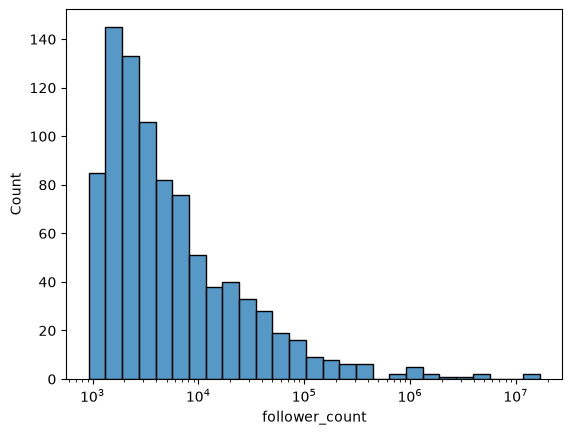

In [8]:
sns.histplot(df_creators["follower_count"], log_scale=True)
plt.show()

Заметим, что столбец enterprise_verified не содержит ни одного Not Null значения. Дропнем его

In [9]:
df_creators["enterprise_verified"].isna().sum()
df_creators = df_creators.drop(columns=["enterprise_verified"])

df_creators

,author_id,date,follower_count,following_count,total_favorited,video_count
73,1008189,2025-01-17,1104.0,447.0,1802.0,95.0
777,10245051,2025-01-17,2011.0,1115.0,86996.0,151.0
1176,1050702,2025-01-04,1428.0,2290.0,6209.0,339.0
2334,10851564,2025-01-17,2640.0,565.0,24430.0,51.0
3817,1133084,2024-08-18,4889.0,4847.0,9988.0,43.0
...,...,...,...,...,...,...
933403,9029993,2025-01-17,32386.0,1414.0,1332406.0,1679.0
934202,9108258,2024-07-28,10759.0,525.0,104584.0,78.0
934770,9115770,2025-01-08,1824.0,422.0,25838.0,156.0
935466,9176597,2025-01-17,1214.0,28.0,13975.0,21.0


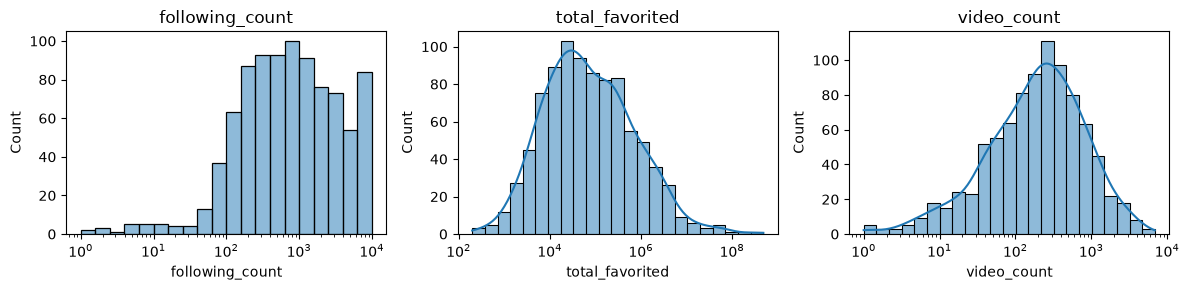

Video Count Describe
 count     896.000000
mean      436.927455
std       663.111043
min         1.000000
25%        75.000000
50%       214.500000
75%       502.500000
max      6873.000000
Name: video_count, dtype: float64 


Total Favorited Describe
 count    8.960000e+02
mean     1.817333e+06
std      1.870552e+07
min      1.980000e+02
25%      1.438450e+04
50%      6.027800e+04
75%      3.177385e+05
max      4.856911e+08
Name: total_favorited, dtype: float64


In [15]:
cols = ["following_count", "total_favorited", "video_count"]
fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, col in zip(axes, cols):
    sns.histplot(df_creators[col], log_scale=True, kde=True, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

print("Video Count Describe\n", df_creators["video_count"].describe(), "\n\n")
print("Total Favorited Describe\n", df_creators["total_favorited"].describe())

Заметим, что есть сильняя корреляция между ``total_favorited`` и ``follower_count``. Интерпретация такая: чем больше подписчиков у человека, тем больше вероятность, что его видео добавят в "Favorite". Остальные столбцы имеют слабую корреляцию, однако стоит заметить, что выборка креаторов после дедубликации не такая большая.

<Axes: >

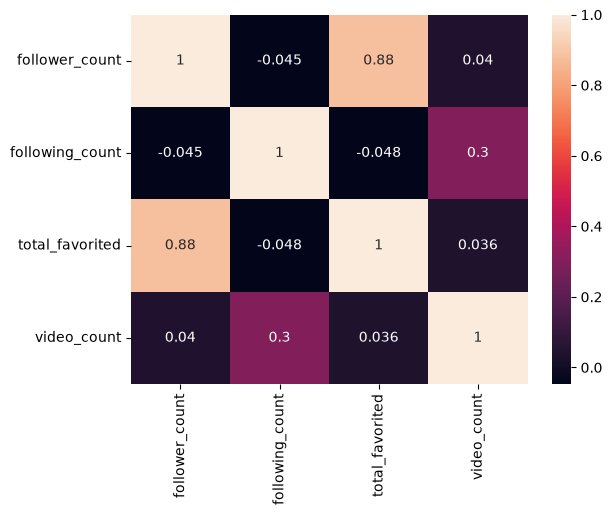

In [ ]:
sns.heatmap(df_creators.select_dtypes(exclude="str").corr(), annot=True)

In [23]:
df_creators.isna().sum()

author_id          0
date               0
follower_count     0
following_count    0
total_favorited    0
video_count        0
dtype: int64

### Videos

Это датасет с самими видео 

In [30]:
df_videos.shape

(1035817, 19)

Каждое видео – уникальное

In [34]:
df_videos = df_videos.drop_duplicates(subset=["video_id"], keep="last")

df_videos.shape

(1035817, 19)

In [35]:
df_videos.sample(4, random_state=RANDOM_STATE)

,video_id,author_id,create_time,create_date,duration,ratio,desc_language,is_english,desc,sticker_text,hashtags,created_by_ai,is_ads,music_selected_from,music_album,music_author,music_owner_id,music_id,music_title
153951,7392669932464524586,6849140798865900550,2024-07-17 13:15:05,2024-07-17,0.000,720p,un,0,NaN,NaN,[],0.0,0,edit_page_unfolded_category,Te Olvidaste de Mi,Luis Gonzalez El Bachatero,NaN,6807928615506823169,Te Olvidaste de Mi
240243,7400930389818117407,8350659,2024-08-08 19:29:54,2024-08-08,585.867,540p,en,1,Episode 2 Part 1 of 3 Web of Evil Shinzo #shin...,Episode 2 Part 1 of 3\nWeb of Evil Shinzo,"[{'hashtag_id': '12299', 'hashtag_name': 'game...",0.0,0,original,NaN,Cordero Vexacus Spencer,8350659,7400930362483919647,original sound - vexacus4666
876813,7466412517049355550,3324795,2025-02-01 05:36:45,2025-02-01,0.000,720p,en,1,Why is respect so powerful? Being respected by...,NaN,"[{'hashtag_id': '1643770238522374', 'hashtag_n...",0.0,0,edit_page_search,NaN,ALEXA RAE,227682125485944832,7240145032894876459,Bossy by Kelis
396882,7416318820480011550,7116966969319883819,2024-09-19 06:44:55,2024-09-19,12.470,540p,es,0,diversión,NaN,[],0.0,0,single_song,NaN,El Click De La Risa,7285550040495522821,7399338592507595525,original sound - elas.garcia1


In [36]:
df_videos.info()

<class 'pandas.DataFrame'>
RangeIndex: 1035817 entries, 0 to 1035816
Data columns (total 19 columns):
 #   Column               Non-Null Count    Dtype  
---  ------               --------------    -----  
 0   video_id             1035817 non-null  str    
 1   author_id            1035817 non-null  str    
 2   create_time          1035817 non-null  str    
 3   create_date          1035817 non-null  str    
 4   duration             1035817 non-null  float64
 5   ratio                1035817 non-null  str    
 6   desc_language        1035817 non-null  str    
 7   is_english           1035817 non-null  int64  
 8   desc                 843799 non-null   str    
 9   sticker_text         418306 non-null   str    
 10  hashtags             1035817 non-null  object 
 11  created_by_ai        1035813 non-null  float64
 12  is_ads               1035817 non-null  str    
 13  music_selected_from  1017504 non-null  str    
 14  music_album          242881 non-null   str    
 15  music_aut

In [40]:
df_videos["ratio"].value_counts()

ratio
540p     855406
720p     173751
480p       4658
360p       1931
1080p        46
240p         24
2160p         1
Name: count, dtype: int64

In [57]:
df_videos.isna().sum()

video_id                    0
author_id                   0
create_time                 0
create_date                 0
duration                    0
ratio                       0
desc_language               0
is_english                  0
desc                        0
sticker_text           617511
hashtags                    0
created_by_ai               4
is_ads                      0
music_selected_from     18313
music_album            792936
music_author             4292
music_owner_id         264804
music_id                 3013
music_title              3478
dtype: int64

Заметим, что ``desc`` – это просто описание видео, если оно None, можно просто приписать пустую строку

In [56]:
df_videos = df_videos.fillna(value={"desc": ""})
df_videos["desc"].info()

<class 'pandas.Series'>
RangeIndex: 1035817 entries, 0 to 1035816
Series name: desc
Non-Null Count    Dtype
--------------    -----
1035817 non-null  str  
dtypes: str(1)
memory usage: 111.0 MB
